# Analisis Kualitas Udara dan Kasus Pernapasan

Notebook ini membaca CSV, membersihkan data, melakukan EDA, dan menguji hubungan antarvariabel.

## 1. Upload dataset

Jalankan cell berikut, lalu pilih file `indonesia_air_quality_health (2).csv`.

In [ ]:
import glob
import io
import os
import pandas as pd

# Colab: tampilkan dialog upload. Kaggle/local: cari CSV otomatis.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.lower().endswith('.csv')]
    if not csv_files:
        raise ValueError('Pilih file CSV, bukan file .py atau .ipynb.')
    FILE = csv_files[0]
    df = pd.read_csv(io.BytesIO(uploaded[FILE]))
except ImportError:
    candidates = (glob.glob('/kaggle/input/**/*.csv', recursive=True) +
                  glob.glob('*.csv') +
                  glob.glob('/home/munas/Downloads/*.csv'))
    if not candidates:
        raise FileNotFoundError('Tambahkan file CSV melalui Add Data di Kaggle.')
    preferred = [p for p in candidates if 'air_quality_health' in os.path.basename(p)]
    FILE = preferred[0] if preferred else candidates[0]
    df = pd.read_csv(FILE)

print(f'File: {FILE}')
print(f'Ukuran data: {df.shape[0]} baris x {df.shape[1]} kolom')
df.head()

File: /home/munas/Downloads/indonesia_air_quality_health (2).csv
Ukuran data: 5000 baris x 12 kolom


,record_id,timestamp,city,zone_type,temperature_c,rainfall_mm,traffic_index,pm25_ug_m3,no2_ppb,aqi_score,air_quality_status,respiratory_cases
0,AQI-10000,2026-08-25 00:00,Jakarta Pusat,Traffic,24.7,0.0,59.9,76.2,72.2,103,Unhealthy for Sensitive Groups,80
1,AQI-10001,2026-08-25 00:00,Bekasi,Industrial,27.9,0.8,39.6,60.0,50.3,81,Moderate,57
2,AQI-10002,2026-08-25 00:00,Tangerang,Industrial,26.3,0.0,64.9,92.7,74.4,125,Unhealthy for Sensitive Groups,75
3,AQI-10003,2026-08-25 00:00,Depok,Residential,25.1,0.0,36.9,47.5,36.7,64,Moderate,39
4,AQI-10004,2026-08-25 00:00,Bandung,Traffic,26.9,0.0,74.6,46.2,65.6,82,Moderate,58


## 2. Pemeriksaan dan pembersihan data

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
print('Kolom:', list(df.columns))
print('Data kosong sebelum dibersihkan:')
print(df.isna().sum().sort_values(ascending=False))

df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
numeric_cols = [
    'temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3',
    'no2_ppb', 'aqi_score', 'respiratory_cases'
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print('Data kosong setelah dibersihkan:')
print(df.isna().sum().sort_values(ascending=False))
df.describe(include='all').T

Kolom: ['record_id', 'timestamp', 'city', 'zone_type', 'temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3', 'no2_ppb', 'aqi_score', 'air_quality_status', 'respiratory_cases']
Data kosong sebelum dibersihkan:
traffic_index         50
pm25_ug_m3            50
temperature_c         50
record_id              0
zone_type              0
city                   0
timestamp              0
rainfall_mm            0
no2_ppb                0
aqi_score              0
air_quality_status     0
respiratory_cases      0
dtype: int64
Data kosong setelah dibersihkan:
record_id             0
timestamp             0
city                  0
zone_type             0
temperature_c         0
rainfall_mm           0
traffic_index         0
pm25_ug_m3            0
no2_ppb               0
aqi_score             0
air_quality_status    0
respiratory_cases     0
dtype: int64


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
record_id,5000,5000,AQI-10000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,5000,NaN,NaN,NaN,2026-09-25 04:30:00,2026-08-25 00:00:00,2026-09-09 14:15:00,2026-09-25 04:30:00,2026-10-10 18:45:00,2026-10-26 09:00:00,NaN
city,5000,10,Jakarta Pusat,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zone_type,5000,3,Industrial,2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature_c,5000.0,NaN,NaN,NaN,27.5441,21.0,25.0,26.4,30.8,35.2,3.167219
rainfall_mm,5000.0,NaN,NaN,NaN,1.14316,0.0,0.0,0.0,0.0,52.0,3.660508
traffic_index,5000.0,NaN,NaN,NaN,53.21498,10.0,38.9,50.9,67.025,100.0,19.181568
pm25_ug_m3,5000.0,NaN,NaN,NaN,57.77384,8.9,47.375,58.5,68.6,105.9,14.875444
no2_ppb,5000.0,NaN,NaN,NaN,61.65806,8.0,48.7,61.5,73.8,116.4,18.05008
aqi_score,5000.0,NaN,NaN,NaN,83.8018,23.0,69.0,85.0,98.0,146.0,20.788029


## 3. Ringkasan kota dan zona

In [3]:
print('Rata-rata berdasarkan kota:')
display(df.groupby('city')[['aqi_score', 'pm25_ug_m3', 'respiratory_cases']]
        .mean().sort_values('aqi_score', ascending=False).round(2))

print('Rata-rata berdasarkan tipe zona:')
display(df.groupby('zone_type')[['aqi_score', 'pm25_ug_m3', 'respiratory_cases']]
        .mean().sort_values('aqi_score', ascending=False).round(2))

Rata-rata berdasarkan kota:


,aqi_score,pm25_ug_m3,respiratory_cases
city,,,
Jakarta Pusat,97.23,62.35,83.02
Bekasi,93.48,68.18,69.42
Bandung,91.63,58.51,71.39
Medan,90.22,60.94,59.77
Tangerang,88.87,64.19,63.93
Surabaya,87.78,62.01,66.24
Semarang,78.81,55.54,46.52
Palembang,78.78,57.95,44.28
Depok,68.83,46.94,46.64


Rata-rata berdasarkan tipe zona:


,aqi_score,pm25_ug_m3,respiratory_cases
zone_type,,,
Traffic,93.03,60.60,71.39
Industrial,87.23,62.48,61.52
Residential,70.00,48.67,41.98


## 4. Visualisasi

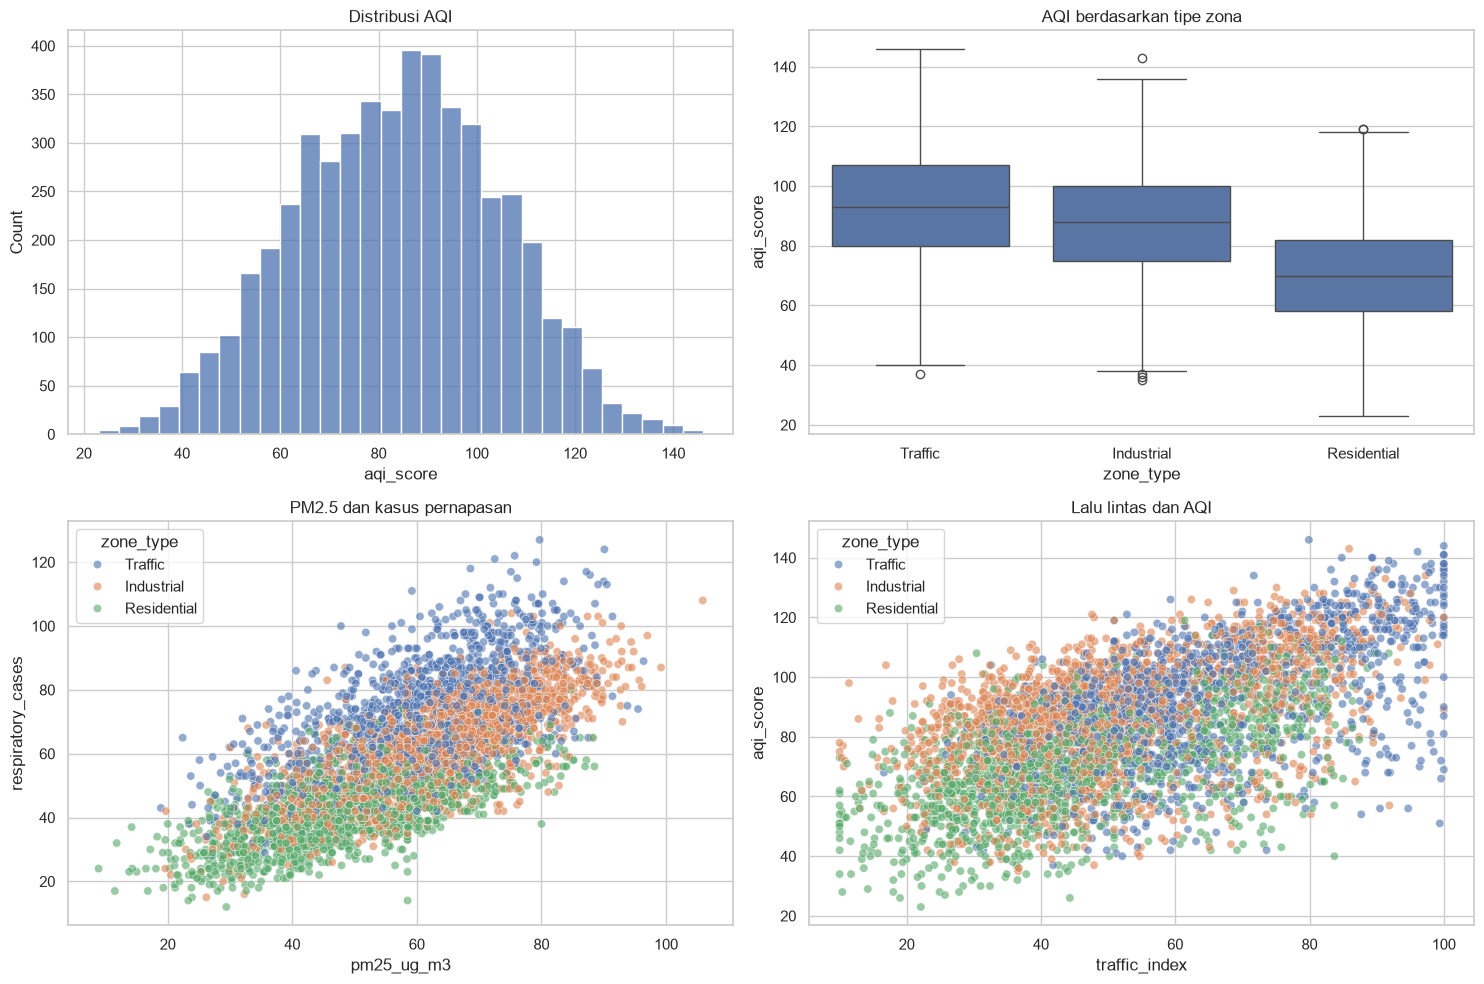

Korelasi dengan kasus pernapasan:


,respiratory_cases
respiratory_cases,1.000
aqi_score,0.819
no2_ppb,0.792
pm25_ug_m3,0.711
traffic_index,0.480
temperature_c,-0.099
rainfall_mm,-0.228


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(data=df, x='aqi_score', bins=30, ax=axes[0, 0])
axes[0, 0].set_title('Distribusi AQI')
sns.boxplot(data=df, x='zone_type', y='aqi_score', ax=axes[0, 1])
axes[0, 1].set_title('AQI berdasarkan tipe zona')
sns.scatterplot(data=df, x='pm25_ug_m3', y='respiratory_cases', hue='zone_type', alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title('PM2.5 dan kasus pernapasan')
sns.scatterplot(data=df, x='traffic_index', y='aqi_score', hue='zone_type', alpha=0.6, ax=axes[1, 1])
axes[1, 1].set_title('Lalu lintas dan AQI')
plt.tight_layout()
plt.show()

print('Korelasi dengan kasus pernapasan:')
display(df[numeric_cols].corr()[['respiratory_cases']].sort_values('respiratory_cases', ascending=False).round(3))

## 5. Uji statistik dan indikator risiko

Proporsi pengamatan dengan AQI berisiko:
risk_aqi
AQI <= 100    0.786
AQI > 100     0.214
Name: proportion, dtype: float64
Rata-rata kasus saat AQI aman: 52.82
Rata-rata kasus saat AQI berisiko: 79.91
Mann-Whitney U p-value: 0.0
Kruskal-Wallis antar zona p-value: 0.0


,variabel,spearman_rho,p_value
5,aqi_score,0.8109,0.0
4,no2_ppb,0.7785,0.0
3,pm25_ug_m3,0.7161,0.0
2,traffic_index,0.4607,0.0
0,temperature_c,-0.0975,0.0
1,rainfall_mm,-0.2654,0.0


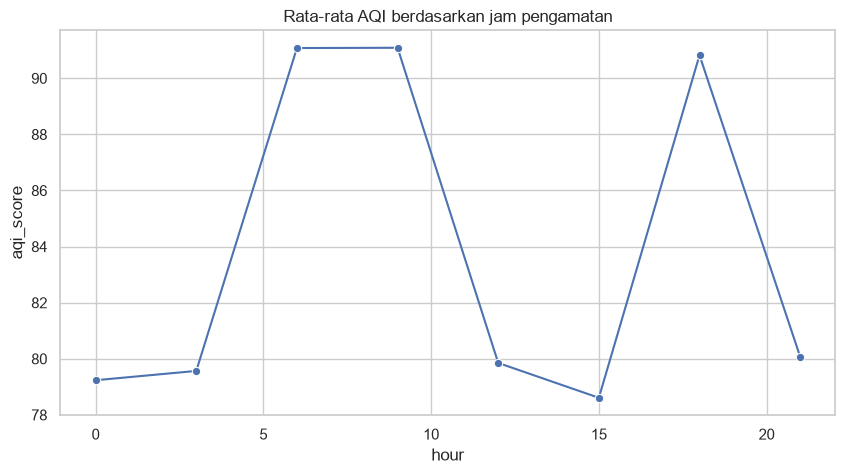

In [5]:
from scipy.stats import spearmanr, mannwhitneyu, kruskal

df['risk_aqi'] = df['aqi_score'] > 100
df['hour'] = df['timestamp'].dt.hour
df['rain_category'] = np.where(df['rainfall_mm'] > 0, 'Hujan', 'Tidak hujan')

print('Proporsi pengamatan dengan AQI berisiko:')
print(df['risk_aqi'].value_counts(normalize=True).rename({False: 'AQI <= 100', True: 'AQI > 100'}).round(3))

aman = df.loc[~df['risk_aqi'], 'respiratory_cases']
berisiko = df.loc[df['risk_aqi'], 'respiratory_cases']
u_stat, p_value = mannwhitneyu(aman, berisiko, alternative='two-sided')
print('Rata-rata kasus saat AQI aman:', round(aman.mean(), 2))
print('Rata-rata kasus saat AQI berisiko:', round(berisiko.mean(), 2))
print('Mann-Whitney U p-value:', round(p_value, 5))

groups = [g['respiratory_cases'].values for _, g in df.groupby('zone_type')]
h_stat, zone_p = kruskal(*groups)
print('Kruskal-Wallis antar zona p-value:', round(zone_p, 5))

corr_cols = ['temperature_c', 'rainfall_mm', 'traffic_index', 'pm25_ug_m3', 'no2_ppb', 'aqi_score', 'respiratory_cases']
corr_result = []
for col in corr_cols[:-1]:
    rho, p = spearmanr(df[col], df['respiratory_cases'])
    corr_result.append({'variabel': col, 'spearman_rho': rho, 'p_value': p})
display(pd.DataFrame(corr_result).sort_values('spearman_rho', ascending=False).round(4))

plt.figure(figsize=(10, 5))
sns.lineplot(data=df.groupby('hour', as_index=False)[['aqi_score', 'respiratory_cases']].mean(), x='hour', y='aqi_score', marker='o')
plt.title('Rata-rata AQI berdasarkan jam pengamatan')
plt.show()

## Kesimpulan sementara

Gunakan tabel kota, tabel zona, grafik, p-value, dan korelasi sebagai bahan laporan. Hasil p-value < 0,05 menunjukkan asosiasi yang signifikan secara statistik. Jangan mengklaim hubungan sebab-akibat hanya dari korelasi.